# Quartz / air / Si three-layer THz-TDS fit with frequency-dependent $n(\omega)$, $k(\omega)$

Three-layer version of `QuartzSI_dispersive_Adam.ipynb` for the new stack **quartz (1 mm) / air gap (~50 µm) / silicon (0.4 mm)**
(**run 3**: `ref_3.txt`, `quartz_air_silicon_15_min_3.txt`, Menlo ScanControl, 21 Oct 2026, 3000-waveform average, 115 ps window —
the same stack re-measured; run 2 of 20 Oct is `QuartzAirSi_dispersive_Adam.ipynb`).

The model, loss, optimizer and plots are the same as in the two-layer notebook; the only change is that the model class
now takes a list of layers with per-layer *freeze* flags (`dispersive_multilayer.py`, `Simulate.py` imported unchanged):

$$
n_j(f) = c_0 + a\,x + b\,x^2 + c\,x^3, \qquad k_j(f) = c_0 + a\,x + b\,x^2, \qquad
x = \frac{\mathrm{clip}(f, f_{lo}, f_{hi}) - f_{ref}}{f_{scale}}
$$

* **Quartz** and **Si**: $n(f)$, $k(f)$ and $d$ all free (as before).
* **Air**: $n = 1$, $k = 0$ **fixed**; only the gap thickness $d_{air}$ is fitted (start 50 µm). Its Adam step scale is set
  to 200 µm (instead of the default "init value" 50 µm) so that the gap can move ~20 nm per iteration; with the default
  scale the gap ramps at Adam's maximum rate for the whole of stage 1 and the other parameters wander while they wait for it.

The air gap is far too thin to show up as a separate echo (round trip ≈ 0.33 ps); it acts as a thin etalon between the
quartz and the Si, i.e. it modulates the amplitude and phase of the quartz→Si interface reflection. Its thickness is
therefore determined only by the shape of the Fabry-Pérot echoes, not by the main-pulse delay.

Stages, as before: **flat** ($c_0$, $d$ only) → **dispersive** (unlock $a, b, c$ of $n$ and $a, b$ of $k$).

In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))

In [2]:
try:
    import ipympl  # noqa
    %matplotlib widget
except ImportError:
    %matplotlib inline

In [3]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch

from Simulate import simulate_from_signal
from dispersive_multilayer import (Grid, DispersiveMultiLayer, simulate_dispersive, poly, fit, total_loss,
                                   N_COEF_NAMES, K_COEF_NAMES)
from data_quartz_air_si import load_run
RUN = 'run3'
t_r, A_r, A_s = load_run(RUN)

torch.set_default_dtype(torch.float32)
c_light = 299792458.0

## 1. Data

L = 3486, dt = 33.0 fs, window = 115.0 ps, df = 2.17 GHz
main-peak delay sample - reference = 6.270 ps


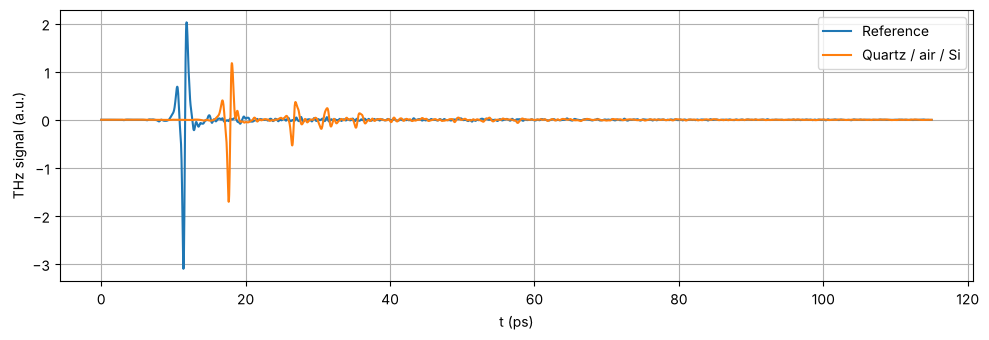

In [4]:
L = len(A_r)
deltat = (t_r[1] - t_r[0]) * 1e-12
t_r = t_r - t_r[0]

x_exp = np.asarray(A_r, dtype=np.float32)          # reference pulse
true_x_exp = np.asarray(A_s, dtype=np.float32)     # sample pulse

F_REF, F_SCALE = 1.0, 1.0        # THz : c0 is the index at F_REF
F_LO, F_HI = 0.2, 3.0            # THz : fit band (checked against the spectrum below)

grid = Grid(L, deltat, f_ref=F_REF, f_scale=F_SCALE, f_lo=F_LO, f_hi=F_HI)
f_np = grid.f_np
print(f"L = {L}, dt = {deltat*1e15:.1f} fs, window = {t_r[-1]:.1f} ps, df = {grid.deltaf/1e9:.2f} GHz")

i_r, i_s = np.argmin(x_exp), np.argmin(true_x_exp)
print(f"main-peak delay sample - reference = {t_r[i_s] - t_r[i_r]:.3f} ps")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t_r, x_exp, label='Reference'); ax.plot(t_r, true_x_exp, label='Quartz / air / Si')
ax.set_xlabel('t (ps)'); ax.set_ylabel('THz signal (a.u.)'); ax.legend(); ax.grid(); plt.tight_layout(); plt.show()

## 2. Consistency check of the 3-layer simulator against `Simulate.simulate_from_signal`

In [5]:
layers_flat = [(1.982 - 0.0071j, 1e-3), (1.0 - 0j, 50e-6), (3.4 - 0.0054j, 0.4e-3)]
_, y_old = simulate_from_signal(x_exp, layers_flat, deltat)
_, y_new = simulate_dispersive(grid, x_exp, [(torch.tensor(n), torch.tensor(d)) for n, d in layers_flat])
print("max |y_new - y_old| =", (y_new - y_old).abs().max().item(), " (should be ~1e-7)")

max |y_new - y_old| = 0.0  (should be ~1e-7)


## 3. Where is the signal? (choose $f_{lo}$, $f_{hi}$)

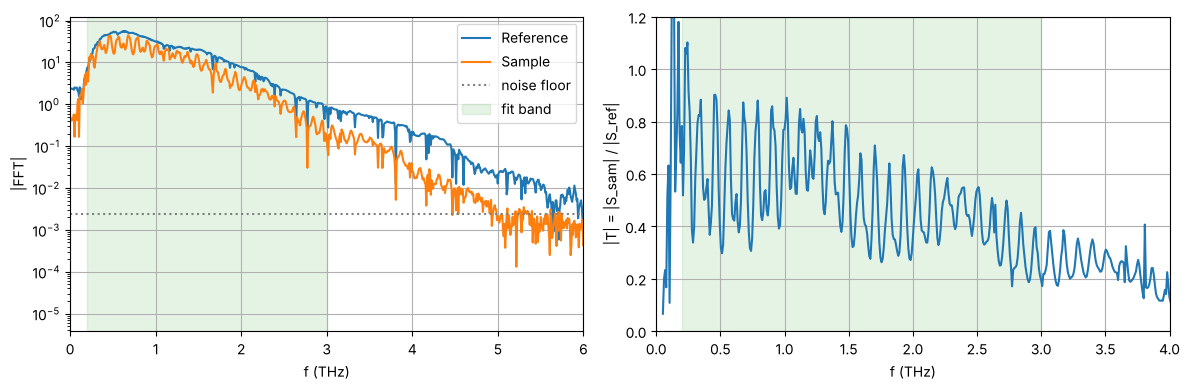

In [6]:
f_data = np.fft.rfftfreq(L, deltat) / 1e12
S_ref = np.abs(np.fft.rfft(x_exp))
S_sam = np.abs(np.fft.rfft(true_x_exp))
noise_floor = np.median(S_ref[f_data > 6.0])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(f_data, S_ref, label='Reference')
ax[0].semilogy(f_data, S_sam, label='Sample')
ax[0].axhline(noise_floor, color='gray', ls=':', label='noise floor')
ax[0].axvspan(F_LO, F_HI, color='C2', alpha=0.12, label='fit band')
ax[0].set_xlim(0, 6); ax[0].set_xlabel('f (THz)'); ax[0].set_ylabel('|FFT|'); ax[0].legend(); ax[0].grid()

ok = (f_data > 0.05)
ax[1].plot(f_data[ok], (S_sam / S_ref)[ok])
ax[1].axvspan(F_LO, F_HI, color='C2', alpha=0.12)
ax[1].set_xlim(0, 4); ax[1].set_ylim(0, 1.2); ax[1].set_xlabel('f (THz)'); ax[1].set_ylabel('|T| = |S_sam| / |S_ref|'); ax[1].grid()
plt.tight_layout(); plt.show()

## 4. Three-layer model

Each layer is a dict `name, n, k, d, fit_n, fit_k, fit_d`. For the air gap `fit_n = fit_k = False` keeps $n = 1$, $k = 0$
exactly (the mask multiplies the trainable `raw` by 0, so Adam never touches them); its thickness stays free.

In [7]:
layer_specs = [
    dict(name='quartz', n=1.9820, k=0.0071, d=1.0e-3),
    dict(name='air',    n=1.0,    k=0.0,    d=50e-6,  fit_n=False, fit_k=False, d_scale=200e-6),   # n = 1 fixed, only d_air fitted
    dict(name='Si',     n=3.4000, k=0.0054, d=0.4e-3),
]

FIT_THICKNESS = True
N_ITERS_FLAT = 15000
N_ITERS_DISP = 30000
LR = 1e-4
K_POS_WEIGHT = 1.0      # soft k >= 0 nudge, same as the two-layer notebook

## 5. Plot helpers

In [8]:
def mae_loss(y_test, y_pred):
    return np.mean(np.abs(y_test - y_pred))

def plot_loss(trajs, labels):
    plt.figure(figsize=(10, 3.5))
    off = 0
    for traj, lab in zip(trajs, labels):
        plt.plot(np.arange(off, off + len(traj['loss'])), traj['loss'], label=lab)
        off += len(traj['loss'])
    off = 0
    for traj, lab in zip(trajs, labels):
        if np.any(traj['penalty'] > 0):
            plt.plot(np.arange(off, off + len(traj['penalty'])), traj['penalty'], ls=':', label=f'{lab}: k-penalty part')
        off += len(traj['loss'])
    plt.yscale('log'); plt.xlabel('Iteration'); plt.ylabel('Loss'); plt.legend(); plt.grid(); plt.title('Optimization')
    plt.show()


def plot_pulses(model, title='Sample pulse: experiment vs dispersive model'):
    with torch.no_grad():
        _, y = model.forward(x_exp)
    y = y.numpy()
    print(f"MAE = {mae_loss(true_x_exp, y):.4e}")
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    ax[0].plot(t_r, true_x_exp, label='Sample Pulse (Experimental)', color='C1')
    ax[0].plot(t_r, y, label='Sample Pulse (Simulated, n(f), k(f))', color='black', alpha=0.75, ls='--')
    ax[0].set_title(title); ax[0].legend(); ax[0].grid()
    ax[1].plot(t_r, true_x_exp - y, color='C3', lw=0.8); ax[1].set_ylabel('residual'); ax[1].set_xlabel('t (ps)'); ax[1].grid()
    plt.tight_layout(); plt.show()


def plot_nk(models, labels, f_plot=np.linspace(0.05, 4.0, 400), which=(0, 2)):
    '''n(f), k(f) of the fitted (non-frozen) layers; the fit band is shaded.'''
    fig, ax = plt.subplots(2, len(which), figsize=(6 * len(which), 7))
    for m, lab in zip(models, labels):
        with torch.no_grad():
            n, k = m.nk(f_plot)
        for col, j in enumerate(which):
            ax[0, col].plot(f_plot, n[j].numpy(), label=lab)
            ax[1, col].plot(f_plot, k[j].numpy(), label=lab)
    for col, j in enumerate(which):
        for i, q in enumerate(['n', 'k']):
            a = ax[i, col]
            a.axvspan(F_LO, F_HI, color='C2', alpha=0.10)
            a.set_xlabel('f (THz)'); a.set_ylabel(f'{q}(f)'); a.grid(); a.legend()
            if q == 'k': a.axhline(0, color='k', lw=0.6)
        ax[0, col].set_title(f'layer {j+1} ({models[0].names[j]})')
    plt.tight_layout(); plt.show()


def plot_spectral_residual(models, labels):
    plt.figure(figsize=(10, 3.5))
    plt.semilogy(f_data, S_sam, color='gray', alpha=0.5, label='|sample spectrum|')
    for m, lab in zip(models, labels):
        with torch.no_grad():
            _, y = m.forward(x_exp)
        plt.semilogy(f_data, np.abs(np.fft.rfft(true_x_exp - y.numpy())), label=f'|residual| {lab}')
    plt.axvspan(F_LO, F_HI, color='C2', alpha=0.10)
    plt.xlim(0, 5); plt.xlabel('f (THz)'); plt.legend(); plt.grid(); plt.show()


def plot_coef_history(traj, names, title='', which=(0, 2)):
    fig, ax = plt.subplots(2, len(which), figsize=(6 * len(which), 6))
    for col, j in enumerate(which):
        for i, nm in enumerate(N_COEF_NAMES):
            ax[0, col].plot(traj['n'][:, j, i] - traj['n'][0, j, i], label=f'n: {nm} - {nm}(0)')
        for i, nm in enumerate(K_COEF_NAMES):
            ax[1, col].plot(traj['k'][:, j, i] - traj['k'][0, j, i], label=f'k: {nm} - {nm}(0)')
        ax[0, col].set_title(f'{names[j]} {title}'); ax[0, col].legend(fontsize=8); ax[0, col].grid()
        ax[1, col].legend(fontsize=8); ax[1, col].grid(); ax[1, col].set_xlabel('iteration')
    plt.tight_layout(); plt.show()


def plot_thickness_history(trajs, labels, names):
    fig, ax = plt.subplots(1, len(names), figsize=(5 * len(names), 3.5))
    off = 0
    for traj, lab in zip(trajs, labels):
        it = np.arange(off, off + len(traj['d']))
        for j, nm in enumerate(names):
            ax[j].plot(it, traj['d'][:, j] * 1e6, label=lab)
        off += len(traj['d'])
    for j, nm in enumerate(names):
        ax[j].set_title(f'd_{nm}'); ax[j].set_ylabel('um'); ax[j].set_xlabel('iteration'); ax[j].grid(); ax[j].legend()
    plt.tight_layout(); plt.show()

## 6. Stage 1 — flat fit ($c_0$ and $d$ only, air $n=1$ fixed)

[flat] Epoch=     1  loss=3.8664e-02 (k-pen 0.0e+00)  quartz: n=1.98200 k=0.00710 d=1000.0um | air: n=1.00000 k=0.00000 d=50.0um | Si: n=3.40000 k=0.00540 d=400.0um |


fit flat:   0%|          | 0/14999 [00:00<?, ?it/s]

[flat] Epoch=  2500  loss=9.5782e-03 (k-pen 0.0e+00)  quartz: n=1.95006 k=0.00614 d=998.0um | air: n=1.00000 k=0.00000 d=88.9um | Si: n=3.35386 k=0.00453 d=394.7um |


[flat] Epoch=  5000  loss=3.7811e-03 (k-pen 0.0e+00)  quartz: n=1.97757 k=0.00416 d=973.3um | air: n=1.00000 k=0.00000 d=126.7um | Si: n=3.38367 k=0.00276 d=389.9um |


[flat] Epoch=  7500  loss=3.6697e-03 (k-pen 0.0e+00)  quartz: n=1.97208 k=0.00430 d=976.1um | air: n=1.00000 k=0.00000 d=126.7um | Si: n=3.40354 k=0.00164 d=387.6um |


[flat] Epoch= 10000  loss=3.6279e-03 (k-pen 0.0e+00)  quartz: n=1.97563 k=0.00477 d=974.3um | air: n=1.00000 k=0.00000 d=126.7um | Si: n=3.38850 k=0.00080 d=389.3um |


[flat] Epoch= 12500  loss=3.6038e-03 (k-pen 0.0e+00)  quartz: n=1.98198 k=0.00519 d=971.2um | air: n=1.00000 k=0.00000 d=126.7um | Si: n=3.36187 k=0.00014 d=392.4um |


[flat] Epoch= 15000  loss=3.5975e-03 (k-pen 0.0e+00)  quartz: n=1.98542 k=0.00527 d=969.5um | air: n=1.00000 k=0.00000 d=126.7um | Si: n=3.34661 k=0.00000 d=394.2um |
  quartz:  n(x) coefs [c0,a,b,c] = [+1.98542, +0.00000, +0.00000, +0.00000]
           k(x) coefs [c0,a,b]   = [+0.00527, +0.00000, +0.00000]      d =   969.52 um   k<0 in band: 0.0 %
     air:  n(x) coefs [c0,a,b,c] = [+1.00000, +0.00000, +0.00000, +0.00000]   (n, k fixed)
           k(x) coefs [c0,a,b]   = [+0.00000, +0.00000, +0.00000]      d =   126.75 um   k<0 in band: 0.0 %
      Si:  n(x) coefs [c0,a,b,c] = [+3.34661, +0.00000, +0.00000, +0.00000]
           k(x) coefs [c0,a,b]   = [+0.00000, +0.00000, +0.00000]      d =   394.23 um   k<0 in band: 0.0 %
MAE = 3.5671e-03


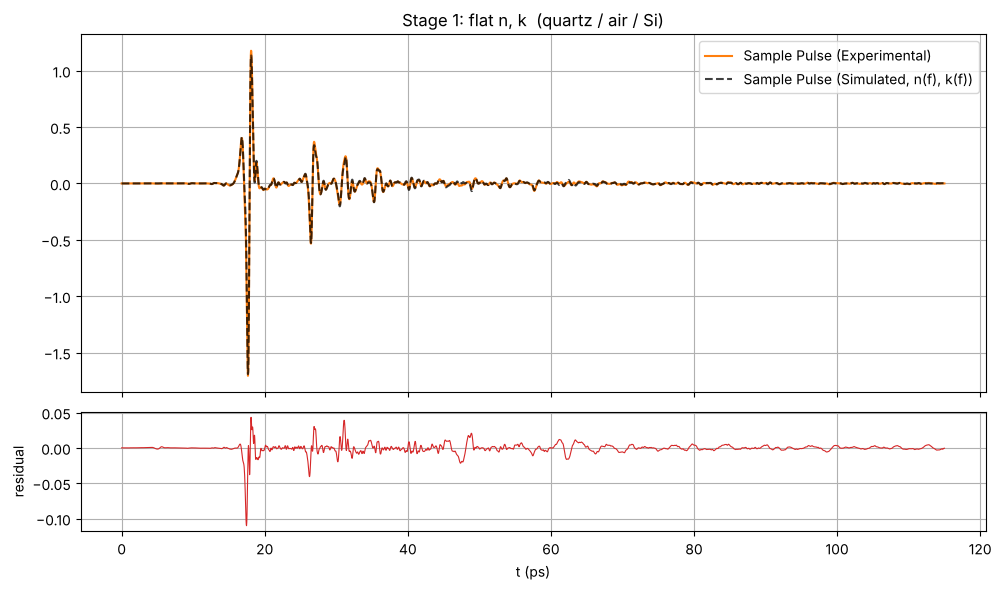

In [9]:
model = DispersiveMultiLayer(grid, layer_specs)
model.set_dispersion(False)
model.set_thickness(FIT_THICKNESS)

traj_flat = fit(model, x_exp, true_x_exp, n_iters=N_ITERS_FLAT, lr=LR, print_step=2500, label='flat', k_pos_weight=K_POS_WEIGHT)
model.report()
plot_pulses(model, title='Stage 1: flat n, k  (quartz / air / Si)')

## 7. Stage 2 — unlock dispersion ($a, b, c$ of $n$ and $a, b$ of $k$ for quartz and Si)

In [10]:
model_flat = copy.deepcopy(model)

model.load_state(model.state())
model.set_dispersion(True)
model.set_thickness(FIT_THICKNESS)

traj_disp = fit(model, x_exp, true_x_exp, n_iters=N_ITERS_DISP, lr=LR, print_step=5000, label='dispersive', k_pos_weight=K_POS_WEIGHT)
model.report()

[dispersive] Epoch=     1  loss=3.5975e-03 (k-pen 0.0e+00)  quartz: n=1.98542 k=0.00527 d=969.5um | air: n=1.00000 k=0.00000 d=126.7um | Si: n=3.34661 k=0.00000 d=394.2um |


fit dispersive:   0%|          | 0/29999 [00:00<?, ?it/s]

[dispersive] Epoch=  5000  loss=3.0862e-03 (k-pen 4.2e-07)  quartz: n=1.98064 k=0.00473 d=972.6um | air: n=1.00000 k=0.00000 d=125.7um | Si: n=3.36321 k=0.00035 d=392.3um |


[dispersive] Epoch= 10000  loss=2.9796e-03 (k-pen 1.8e-08)  quartz: n=1.97712 k=0.00504 d=974.2um | air: n=1.00000 k=0.00000 d=125.7um | Si: n=3.37348 k=0.00012 d=391.1um |


[dispersive] Epoch= 15000  loss=2.9525e-03 (k-pen 0.0e+00)  quartz: n=1.97377 k=0.00514 d=975.9um | air: n=1.00000 k=0.00000 d=125.7um | Si: n=3.38418 k=0.00000 d=389.9um |


[dispersive] Epoch= 20000  loss=2.9503e-03 (k-pen 5.2e-08)  quartz: n=1.97179 k=0.00508 d=976.9um | air: n=1.00000 k=0.00000 d=125.8um | Si: n=3.39269 k=0.00000 d=388.9um |


[dispersive] Epoch= 25000  loss=2.9500e-03 (k-pen 6.3e-08)  quartz: n=1.97097 k=0.00504 d=977.3um | air: n=1.00000 k=0.00000 d=125.8um | Si: n=3.39647 k=0.00000 d=388.4um |


[dispersive] Epoch= 30000  loss=2.9501e-03 (k-pen 8.6e-08)  quartz: n=1.97049 k=0.00503 d=977.5um | air: n=1.00000 k=0.00000 d=125.8um | Si: n=3.39854 k=0.00000 d=388.2um |


  quartz:  n(x) coefs [c0,a,b,c] = [+1.97049, +0.00323, -0.00432, +0.00384]
           k(x) coefs [c0,a,b]   = [+0.00503, +0.00570, -0.00087]      d =   977.54 um   k<0 in band: 0.4 %
     air:  n(x) coefs [c0,a,b,c] = [+1.00000, +0.00000, +0.00000, +0.00000]   (n, k fixed)
           k(x) coefs [c0,a,b]   = [+0.00000, +0.00000, +0.00000]      d =   125.82 um   k<0 in band: 0.0 %
      Si:  n(x) coefs [c0,a,b,c] = [+3.39854, +0.00007, +0.00397, -0.00344]
           k(x) coefs [c0,a,b]   = [+0.00000, +0.00000, +0.00000]      d =   388.20 um   k<0 in band: 0.0 %


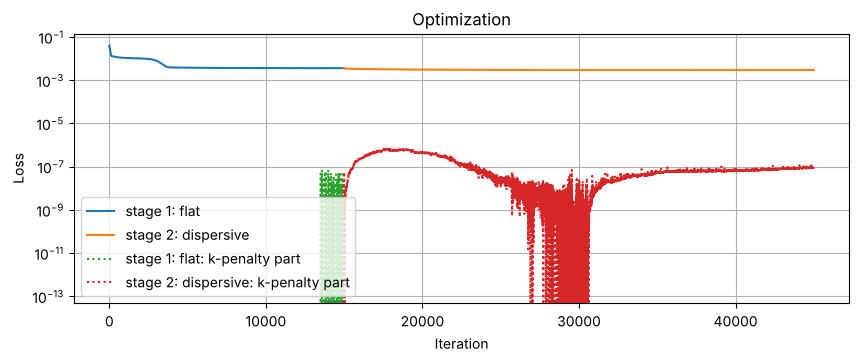

MAE = 2.9338e-03


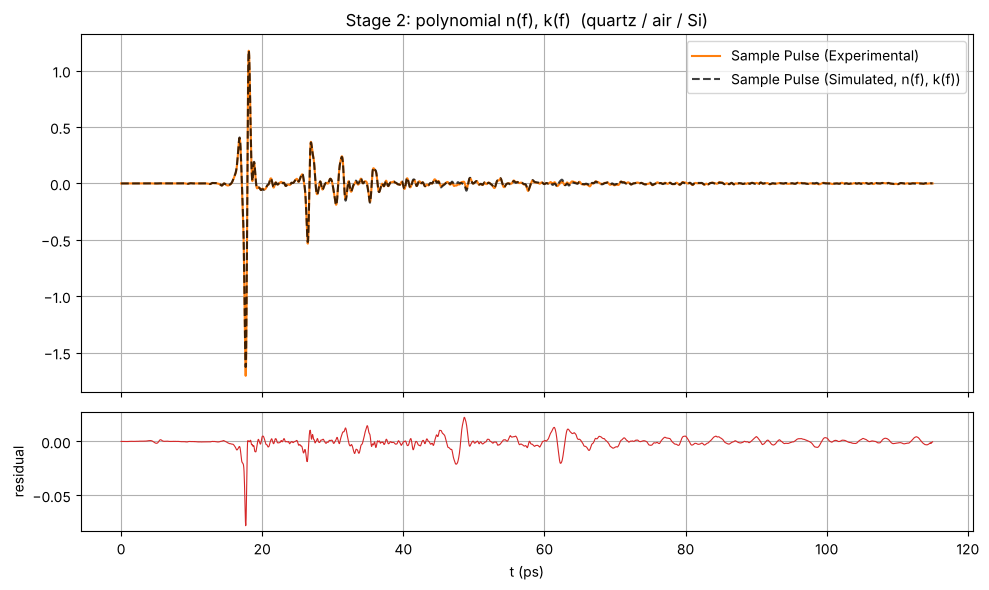

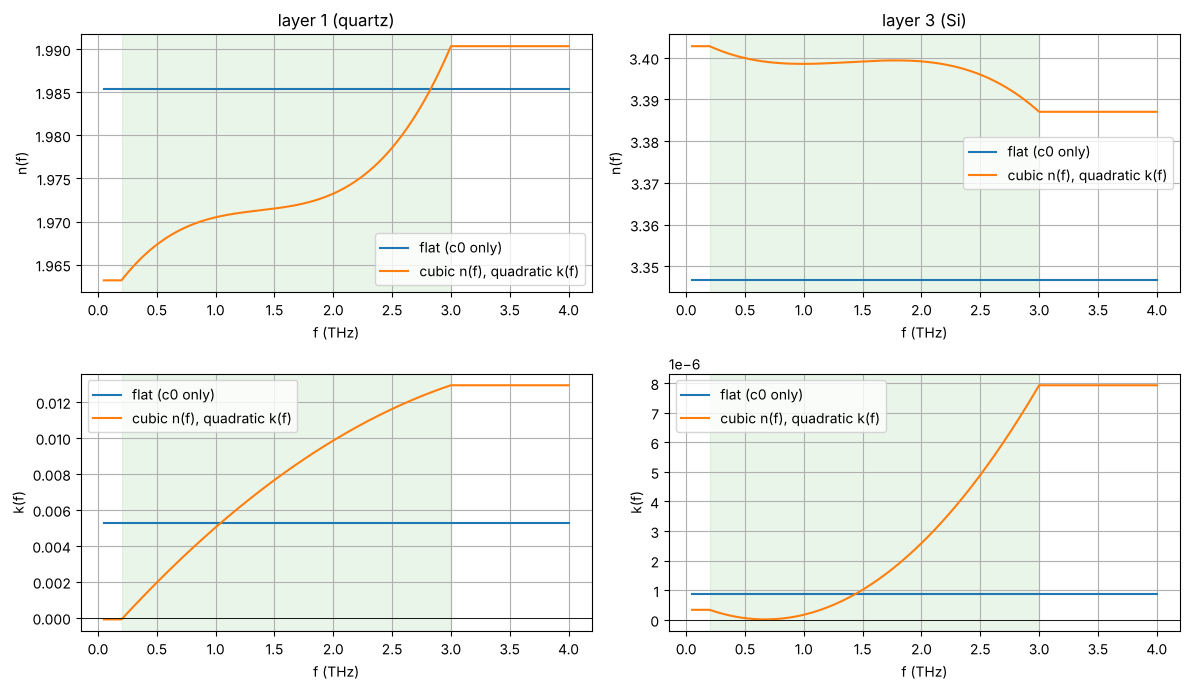

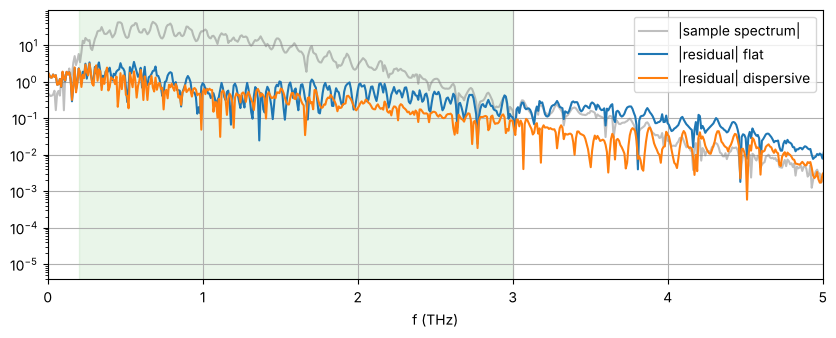

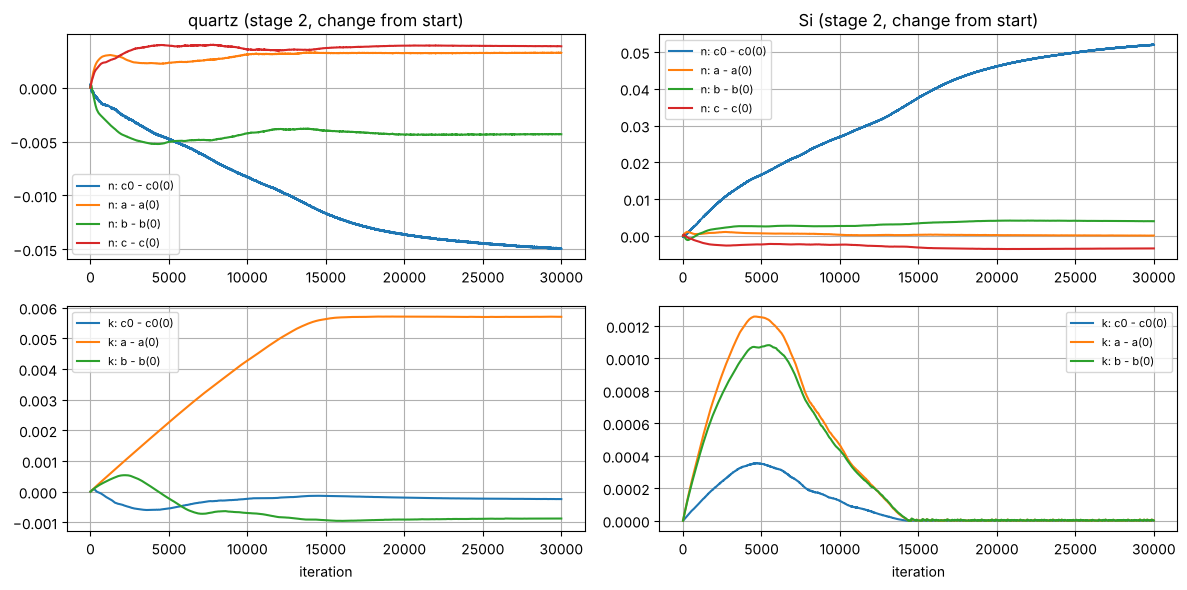

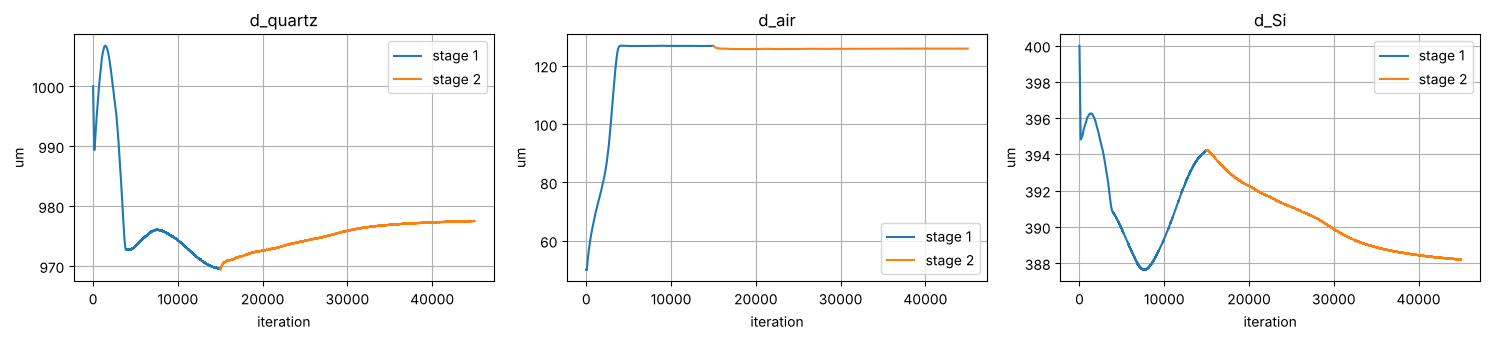

In [11]:
plot_loss([traj_flat, traj_disp], ['stage 1: flat', 'stage 2: dispersive'])
plot_pulses(model, title='Stage 2: polynomial n(f), k(f)  (quartz / air / Si)')
plot_nk([model_flat, model], ['flat (c0 only)', 'cubic n(f), quadratic k(f)'])
plot_spectral_residual([model_flat, model], ['flat', 'dispersive'])
plot_coef_history(traj_disp, model.names, '(stage 2, change from start)')
plot_thickness_history([traj_flat, traj_disp], ['stage 1', 'stage 2'], model.names)

## 8. Comparison with run 2 (same stack, 20 Oct) and the two-layer (no air gap) result

`QuartzAirSi_poly_coefs.npz` is the polynomial fit of run 2 (same stack, previous day); `QuartzSi_poly_coefs.npz` the
earlier quartz/Si measurement without gap. The same materials should come out with the same $n(f)$; the thicknesses are only constrained through the optical
path $n d$ (the usual degeneracy), so compare $n d$ rather than $n$ and $d$ separately.

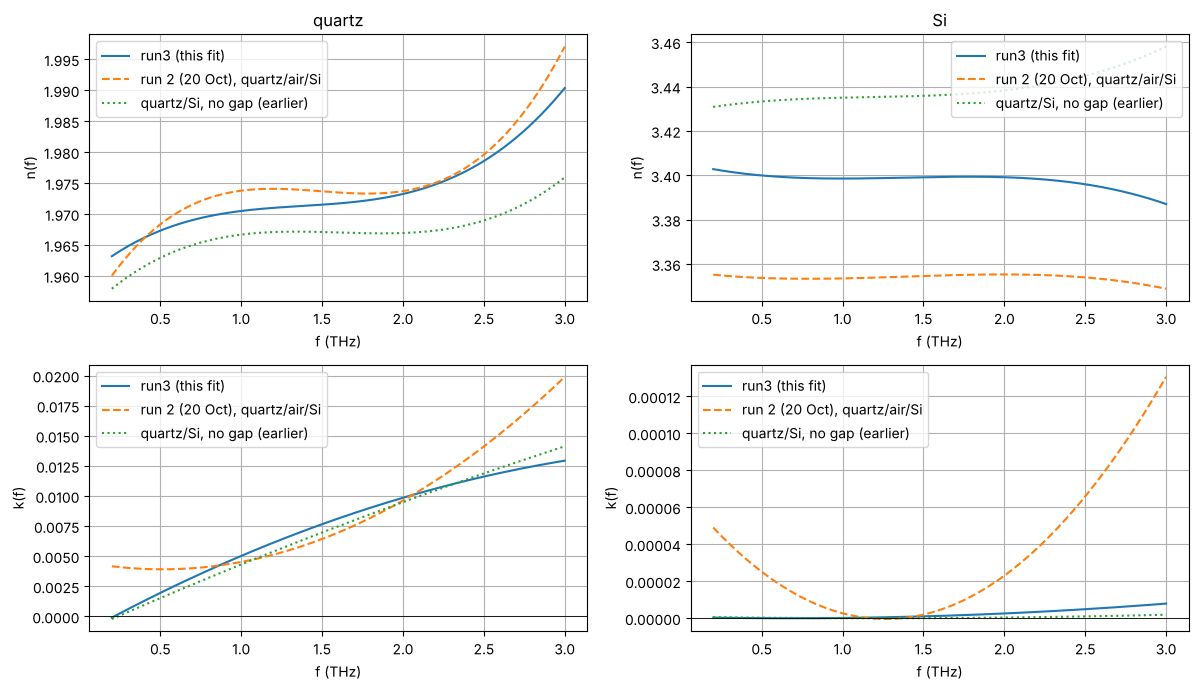

              n_q(1THz)   d_q um  nd_q um | d_air um | n_Si(1THz)  d_Si um nd_Si um
run3             1.9705    977.5   1926.2 |    125.8 |     3.3985    388.2   1319.3
run 2 (20 Oc     1.9738    976.6   1927.5 |    125.1 |     3.3535    393.4   1319.2
quartz/Si, n     1.9667    994.0   1954.8 |        - |     3.4350    382.7   1314.6


In [12]:
import os
f_cmp = np.linspace(F_LO, F_HI, 300)
with torch.no_grad():
    n_new, k_new = model.nk(f_cmp)
st = model.state()

refs = []   # (label, npz, layer index of quartz, layer index of Si, linestyle)
if os.path.exists('QuartzAirSi_poly_coefs.npz'): refs.append(('run 2 (20 Oct), quartz/air/Si', 'QuartzAirSi_poly_coefs.npz', 0, 2, '--'))
if os.path.exists('QuartzSi_poly_coefs.npz'):    refs.append(('quartz/Si, no gap (earlier)', 'QuartzSi_poly_coefs.npz', 0, 1, ':'))

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for col, (j_new, nm) in enumerate([(0, 'quartz'), (2, 'Si')]):
    ax[0, col].plot(f_cmp, n_new[j_new].numpy(), label=f'{RUN} (this fit)')
    ax[1, col].plot(f_cmp, k_new[j_new].numpy(), label=f'{RUN} (this fit)')
    for lab, fn, jq, js, ls in refs:
        old = np.load(fn); j_old = jq if nm == 'quartz' else js
        xo = (np.clip(f_cmp, float(old['F_LO']), float(old['F_HI'])) - float(old['F_REF'])) / float(old['F_SCALE'])
        ax[0, col].plot(f_cmp, poly(old['n_coefs'][j_old], xo), ls, label=lab)
        ax[1, col].plot(f_cmp, poly(old['k_coefs'][j_old], xo), ls, label=lab)
    ax[0, col].set_title(nm); ax[1, col].axhline(0, color='k', lw=0.6)
    for i, q in enumerate(['n', 'k']):
        ax[i, col].set_xlabel('f (THz)'); ax[i, col].set_ylabel(f'{q}(f)'); ax[i, col].grid(); ax[i, col].legend()
plt.tight_layout(); plt.show()

print(f"{'':12s} {'n_q(1THz)':>10s} {'d_q um':>8s} {'nd_q um':>8s} | {'d_air um':>8s} | {'n_Si(1THz)':>10s} {'d_Si um':>8s} {'nd_Si um':>8s}")
def row(lab, n, d, jq, js, ja=None):
    air = f"{d[ja]*1e6:8.1f}" if ja is not None else f"{'-':>8s}"
    print(f"{lab:12s} {n[jq]:10.4f} {d[jq]*1e6:8.1f} {n[jq]*d[jq]*1e6:8.1f} | {air} | {n[js]:10.4f} {d[js]*1e6:8.1f} {n[js]*d[js]*1e6:8.1f}")
row(RUN, st['n'][:, 0].numpy(), st['d'].numpy(), 0, 2, 1)
for lab, fn, jq, js, ls in refs:
    old = np.load(fn); row(lab[:12], old['n_coefs'][:, 0], old['d'], jq, js, 1 if 'air' in lab else None)

## 9. How well are the air gap and the $n$–$d$ splits determined? (loss scans)

(a) loss vs $d_{air}$ with everything else at the fit; (b), (c) $n(1\,\mathrm{THz})$ vs $d$ landscapes (±3 %) for quartz and
Si with the $n d = $ const line, the run-2 solution and the literature HRFZ-Si value marked.

d_air scan: minimum at 126.0 um; loss at 50 um = 1.623e-02 vs 2.954e-03 at the minimum


quartz: loss along the valley (min over d) at n = 1.911: 1.615e-02, 1.935: 7.294e-03, 1.959: 3.828e-03, 1.982: 3.976e-03, 2.006: 7.221e-03, 2.030: 1.411e-02


Si: loss along the valley (min over d) at n = 3.297: 7.793e-03, 3.337: 4.208e-03, 3.378: 3.273e-03, 3.419: 3.377e-03, 3.460: 4.178e-03, 3.501: 6.150e-03


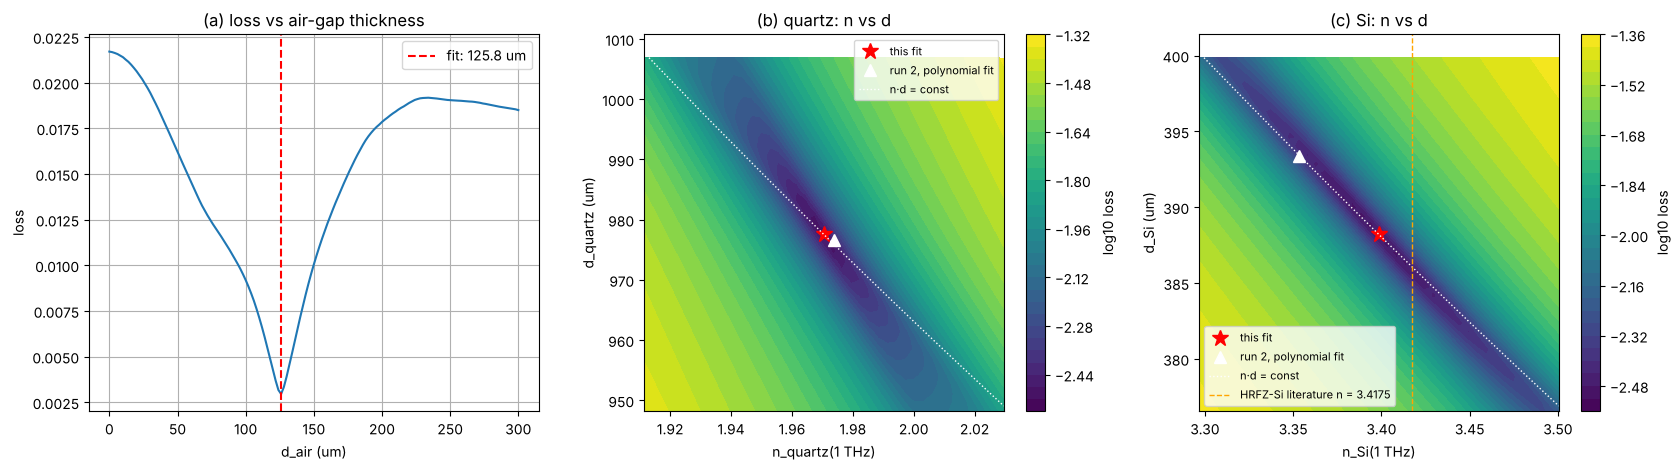

In [13]:
def loss_at(m):
    with torch.no_grad():
        _, y = m.forward(x_exp)
        return total_loss(y, torch.as_tensor(true_x_exp), m, K_POS_WEIGHT).item()

ms = copy.deepcopy(model); ms.load_state(ms.state())
d0 = st['d'].numpy().copy(); n0 = st['n'].numpy().copy()

# (a) air gap
d_scan = np.linspace(0, 300e-6, 151); loss_air = []
for v in d_scan:
    ms.d_init[1] = float(v); loss_air.append(loss_at(ms))
ms.d_init[1] = float(d0[1]); loss_air = np.array(loss_air)
print(f"d_air scan: minimum at {d_scan[loss_air.argmin()]*1e6:.1f} um; loss at 50 um = {loss_air[np.argmin(abs(d_scan-50e-6))]:.3e} "
      f"vs {loss_air.min():.3e} at the minimum")

# (b), (c) n vs d landscapes
def landscape(m, j, span=0.03, npts=41):
    nn = n0[j, 0] * (1 + np.linspace(-span, span, npts)); dd = d0[j] * (1 + np.linspace(-span, span, npts))
    Z = np.zeros((npts, npts))
    for a, nv in enumerate(nn):
        m.n_init[j, 0] = float(nv)
        for b, dv in enumerate(dd):
            m.d_init[j] = float(dv); Z[b, a] = loss_at(m)
    m.n_init[j, 0] = float(n0[j, 0]); m.d_init[j] = float(d0[j])
    return nn, dd, Z

prev_pt = {0: (1.97377, 976.57e-6), 2: (3.35352, 393.38e-6)}     # run 2 polynomial fit (QuartzAirSi_poly_coefs.npz)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(d_scan * 1e6, loss_air); ax[0].axvline(d0[1] * 1e6, color='r', ls='--', label=f'fit: {d0[1]*1e6:.1f} um')
ax[0].set_xlabel('d_air (um)'); ax[0].set_ylabel('loss'); ax[0].set_title('(a) loss vs air-gap thickness'); ax[0].grid(); ax[0].legend()
for col, (j, nm) in enumerate([(0, 'quartz'), (2, 'Si')], start=1):
    nn, dd, Z = landscape(ms, j)
    cf = ax[col].contourf(nn, dd * 1e6, np.log10(Z), 30, cmap='viridis'); plt.colorbar(cf, ax=ax[col], label='log10 loss')
    ax[col].plot(n0[j, 0], d0[j] * 1e6, 'r*', ms=12, label='this fit')
    ax[col].plot(prev_pt[j][0], prev_pt[j][1] * 1e6, 'w^', ms=9, label='run 2, polynomial fit')
    ax[col].plot(nn, n0[j, 0] * d0[j] / nn * 1e6, 'w:', lw=1, label='n·d = const')
    if j == 2: ax[col].axvline(3.4175, color='orange', ls='--', lw=1, label='HRFZ-Si literature n = 3.4175')
    ax[col].set_xlabel(f'n_{nm}(1 THz)'); ax[col].set_ylabel(f'd_{nm} (um)'); ax[col].set_title(f'({"bc"[col-1]}) {nm}: n vs d'); ax[col].legend(fontsize=8)
    print(f"{nm}: loss along the valley (min over d) at n = " + ', '.join(f'{nn[i]:.3f}: {Z[:, i].min():.3e}' for i in range(0, 41, 8)))
plt.tight_layout(); plt.show()

## 10. Export $n(f)$, $k(f)$ tables and coefficients

In [14]:
f_out = np.arange(F_LO, F_HI + 1e-9, 0.01)
with torch.no_grad():
    n_out, k_out = model.nk(f_out)
    n_out, k_out = n_out.numpy(), k_out.numpy()

table = np.column_stack([f_out, n_out[0], k_out[0], n_out[2], k_out[2]])
np.savetxt(f'QuartzAirSi_{RUN}_nk_of_f.txt', table, fmt='%.6e',
           header='f_THz  n_quartz  k_quartz  n_Si  k_Si   (quartz/air/Si polynomial fit, air n=1 fixed, d_air=%.2f um; '
                  'x=(f-%.2f)/%.2f clipped to [%.2f,%.2f] THz)' % (st['d'][1].item()*1e6, F_REF, F_SCALE, F_LO, F_HI))

np.savez(f'QuartzAirSi_{RUN}_poly_coefs.npz', n_coefs=st['n'].numpy(), k_coefs=st['k'].numpy(), d=st['d'].numpy(),
         names=np.array(model.names), F_REF=F_REF, F_SCALE=F_SCALE, F_LO=F_LO, F_HI=F_HI)
print(table[::50])

[[ 2.00000000e-01  1.96316898e+00 -9.03042965e-05  3.40278983e+00
   3.38175141e-07]
 [ 7.00000000e-01  1.96902549e+00  3.24071292e-03  3.39897370e+00
   1.52353437e-08]
 [ 1.20000000e+00  1.97099352e+00  6.13455474e-03  3.39868975e+00
   4.22066734e-07]
 [ 1.70000000e+00  1.97195053e+00  8.59122165e-03  3.39935851e+00
   1.55866917e-06]
 [ 2.20000000e+00  1.97477412e+00  1.06107136e-02  3.39840031e+00
   3.42504291e-06]
 [ 2.70000000e+00  1.98234177e+00  1.21930307e-02  3.39323521e+00
   6.02118735e-06]]


## Notes

* **Air gap**: $n_{air} = 1$, $k_{air} = 0$ are hard-frozen (`fit_n = fit_k = False`); only $d_{air}$ moves. To also pin
  the gap, add `fit_d=False` to its spec. To let $n_{air}$ float (e.g. to absorb a non-planar gap) set `fit_n=True`.
* **Degeneracy**: as in the two-layer case only $n_j d_j$ is tightly fixed by the delays; the Fabry-Pérot echoes
  break it weakly (section 9 b, c). The gap thickness, in contrast, is pinned sharply by the echo shape (section 9 a).
  If the Si thickness (or $n_{Si}$ = 3.4175 for HRFZ Si) is known independently, pin it with `fit_d=False` / `fit_n=False`.
* Everything else (band, polynomial order, scales, $k$ positivity) is as described in `QuartzSI_dispersive_Adam.ipynb`.